# JS06 — Praktikum 2
## Perbandingan Exact Nearest Neighbor dan FAISS IVF+PQ

**Tujuan praktikum**

1. Membuat pencarian tetangga terdekat dengan FAISS `IndexFlatL2` / `IndexFlatIP` (Exact NN).
2. Membuat indeks approximate dengan **Inverted File + Product Quantization** (`IndexIVFPQ`).
3. Membandingkan metrik **Euclidean** dan **Cosine**, jumlah data **1.000 vs 1.000.000**, serta dimensi **2D vs 5D**.
4. Mengamati indeks 3 tetangga terdekat, waktu pencarian, *Recall@3*, dan biaya membangun indeks.
5. Melengkapi tabel percobaan dan menarik kesimpulan berdasarkan hasil aktual.

> **Catatan penting:** Semua angka waktu dan indeks dihasilkan **langsung ketika kode dijalankan** pada komputer pengguna. Tidak ada hasil benchmark yang direkayasa. Durasi dapat berbeda berdasarkan CPU dan lingkungan Colab.

**Rancangan:** 2 metrik × 2 ukuran data × 2 dimensi = **8 percobaan**. Nilai `k=3`, `seed=42`, dan query `[0.5, ..., 0.5]` disamakan agar percobaan dapat diulang. Untuk data besar, tahap train dan add IVF+PQ membutuhkan waktu lebih lama daripada pencarian.

### 0. Instalasi dan import library
Jika menggunakan Google Colab, jalankan sel instalasi sekali. Notebook ini memakai FAISS **CPU**. Instalasi tidak memerlukan GPU.

In [1]:
%pip -q install faiss-cpu numpy pandas matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 48.5 MB/s eta 0:00:00


In [2]:
import gc
import os
import platform
import time

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# Batasi thread agar benchmark kecil tidak didominasi overhead paralelisasi.
faiss.omp_set_num_threads(min(4, os.cpu_count() or 1))
np.set_printoptions(precision=5, suppress=True)

print('Versi FAISS :', getattr(faiss, '__version__', 'tidak diketahui'))
print('Versi NumPy :', np.__version__)
print('Prosesor    :', platform.processor() or platform.machine())
print('Jumlah CPU  :', os.cpu_count())
print('Thread FAISS:', faiss.omp_get_max_threads())

Versi FAISS : 1.15.1
Versi NumPy : 2.1.3
Prosesor    : x86_64
Jumlah CPU  : 2
Thread FAISS: 2


### 1. Fungsi pendukung

- **Euclidean:** FAISS `IndexFlatL2` mengembalikan **squared L2 distance** (kuadrat jarak Euclidean). Nilai lebih kecil berarti lebih dekat.
- **Cosine:** Normalisasi L2 semua vektor dan query, kemudian gunakan `IndexFlatIP`; *inner product* vektor satuan sama dengan *cosine similarity*. Nilai lebih besar berarti lebih mirip.
- **IVF+PQ:** `index_factory` membentuk indeks IVF+PQ dengan tipe metrik yang sesuai. `nprobe` mengatur berapa *inverted list* yang diperiksa.
- **Recall@3:** fraksi indeks yang sama antara tiga hasil Exact dan tiga hasil Approximate.
- **Waktu pencarian:** median 30 kali panggilan pencarian tunggal dengan `perf_counter` (sebelumnya dilakukan *warm-up*). Waktu pembangunan indeks dicatat secara terpisah.

Untuk 1.000 data digunakan `nbits=4` (16 centroid per subkuantizer) agar pembelajaran PQ lebih masuk akal pada dataset kecil. Untuk 1 juta data digunakan `nbits=8` (256 centroid per subkuantizer). Jumlah subvectors PQ dipilih `m=2` untuk 2D dan `m=5` untuk 5D; **dimensi harus habis dibagi `m`**. Konfigurasi ini sengaja menyesuaikan ukuran data. Hasil seluruh eksperimen tetap bisa dibandingkan sebagai demonstrasi, tetapi perbandingan lintas ukuran data juga dipengaruhi konfigurasi indeks.

In [3]:
def generate_data(n_points, dim, seed=42):
    rng = np.random.default_rng(seed)
    X = rng.random((n_points, dim), dtype=np.float32)
    query = np.full((1, dim), 0.5, dtype=np.float32)
    return X, query


def prepare_metric_data(X, query, metric):
    # Copy supaya dataset mentah tetap bisa dipakai untuk dua metrik.
    X_search = np.ascontiguousarray(X.copy(), dtype=np.float32)
    q_search = np.ascontiguousarray(query.copy(), dtype=np.float32)
    if metric == 'Cosine':
        faiss.normalize_L2(X_search)
        faiss.normalize_L2(q_search)
    elif metric != 'Euclidean':
        raise ValueError('Metrik harus Euclidean atau Cosine')
    return X_search, q_search


def create_flat_index(dim, metric):
    if metric == 'Euclidean':
        return faiss.IndexFlatL2(dim)
    return faiss.IndexFlatIP(dim)


def create_ivfpq_index(dim, metric, nlist, m, nbits):
    faiss_metric = faiss.METRIC_L2 if metric == 'Euclidean' else faiss.METRIC_INNER_PRODUCT
    description = f'IVF{nlist},PQ{m}x{nbits}'
    index = faiss.index_factory(dim, description, faiss_metric)
    return index


def median_search_ms(index, query, k=3, repeat=30):
    # Warm-up di luar benchmark.
    for _ in range(3):
        index.search(query, k)
    measurements = []
    for _ in range(repeat):
        t0 = time.perf_counter()
        index.search(query, k)
        measurements.append((time.perf_counter() - t0) * 1000)
    return float(np.median(measurements))


def evaluate_recall(indices_exact, indices_approx):
    actual = {int(i) for i in indices_exact if i >= 0}
    predicted = {int(i) for i in indices_approx if i >= 0}
    return len(actual.intersection(predicted)) / max(len(actual), 1)


def show_scores(D, metric):
    if metric == 'Euclidean':
        return np.sqrt(np.maximum(D, 0)).round(6).tolist()  # jarak L2, bukan kuadratnya
    return D.round(6).tolist()  # similarity cosine (semakin tinggi semakin dekat)

### 2. Fungsi untuk menjalankan satu percobaan

Untuk setiap kombinasi metrik, jumlah data dan dimensi, kode akan:

1. Membuat data acak `float32` dan menyiapkan metrik.
2. Membangun indeks Flat (*exact*) serta mengukur waktu pembuatannya.
3. Melatih dan menambahkan data ke IVF+PQ; **waktu training dan penambahan data turut dicatat**.
4. Mencari `k=3` tetangga, membandingkan hasil dan menghitung median waktu lookup.
5. Menghasilkan nilai *Recall@3* terhadap Exact NN sebagai *ground truth*.

Untuk 1 juta data, training IVF+PQ memakai **sampel 20.000 vektor** agar lebih ringan; indeks tetap menyimpan **seluruh 1 juta data**.

In [4]:
def run_experiment(X_raw, query_raw, metric, dim, k=3, seed=42):
    n = len(X_raw)
    X, query = prepare_metric_data(X_raw, query_raw, metric)

    nlist = 10 if n == 1_000 else 100
    m = dim  # dim 2 -> PQ2; dim 5 -> PQ5
    nbits = 4 if n == 1_000 else 8
    nprobe = 3 if n == 1_000 else 8

    # 1) Exact Flat: add hanya sekali
    t0 = time.perf_counter()
    index_flat = create_flat_index(dim, metric)
    index_flat.add(X)
    exact_build_s = time.perf_counter() - t0
    D_exact, I_exact = index_flat.search(query, k)
    exact_ms = median_search_ms(index_flat, query, k=k)

    # 2) Approximate IVF+PQ: train dahulu sebelum add
    index_pq = create_ivfpq_index(dim, metric, nlist, m, nbits)
    rng = np.random.default_rng(seed + 137)
    n_train = min(n, 20_000)
    train_indices = rng.choice(n, size=n_train, replace=False)
    X_train = np.ascontiguousarray(X[train_indices], dtype=np.float32)

    t0 = time.perf_counter()
    index_pq.train(X_train)
    train_s = time.perf_counter() - t0

    t0 = time.perf_counter()
    # Menambahkan seluruh dataset (bukan hanya training sample)
    index_pq.add(X)
    add_s = time.perf_counter() - t0

    index_pq.nprobe = nprobe
    D_pq, I_pq = index_pq.search(query, k)
    approx_ms = median_search_ms(index_pq, query, k=k)

    indices_exact = I_exact[0].tolist()
    indices_pq = I_pq[0].tolist()
    recall = evaluate_recall(indices_exact, indices_pq)

    result = {
        'Metrik': metric,
        'Jumlah data': n,
        'Dimensi': dim,
        'k': k,
        'nlist': nlist,
        'nprobe': nprobe,
        'PQ m': m,
        'nbits': nbits,
        'Exact NN index': indices_exact,
        'IVF+PQ index': indices_pq,
        'Exact distance/similarity': show_scores(D_exact[0], metric),
        'IVF+PQ distance/similarity': show_scores(D_pq[0], metric),
        'Waktu Exact (ms)': exact_ms,
        'Waktu IVF+PQ (ms)': approx_ms,
        'Recall@3': recall,
        'Build Exact (s)': exact_build_s,
        'Train IVF+PQ (s)': train_s,
        'Add IVF+PQ (s)': add_s,
    }
    result['Speedup Exact/IVF+PQ'] = (
        exact_ms / approx_ms if approx_ms > 0 else float('nan')
    )
    return result, indices_exact, indices_pq

### 3. Percobaan 1 — 1.000 data (2D dan 5D)

Masing-masing dimensi diuji dengan **Euclidean** dan **Cosine**. Tabel memuat empat baris hasil eksperimen.

In [5]:
results_small = []
indices_for_plot = None
X_for_plot = None
q_for_plot = None

for dim in [2, 5]:
    X_raw, query_raw = generate_data(1_000, dim)
    for metric in ['Euclidean', 'Cosine']:
        print(f'Menjalankan: {metric} | n=1,000 | dim={dim} ...')
        result, i_ex, i_pq = run_experiment(X_raw, query_raw, metric, dim)
        results_small.append(result)
        print('  Exact:', i_ex, '| IVF+PQ:', i_pq,
              '| Recall@3:', f"{result['Recall@3']:.3f}")
        if dim == 2 and metric == 'Euclidean':
            indices_for_plot = (i_ex, i_pq)
            X_for_plot = X_raw.copy()
            q_for_plot = query_raw.copy()
    del X_raw, query_raw
    gc.collect()

small_df = pd.DataFrame(results_small)
cols_show = ['Metrik', 'Jumlah data', 'Dimensi', 'Exact NN index',
             'IVF+PQ index', 'Waktu Exact (ms)', 'Waktu IVF+PQ (ms)', 'Recall@3']
display(small_df[cols_show].round(5))

Menjalankan: Euclidean | n=1,000 | dim=2 ...
  Exact: [202, 358, 899] | IVF+PQ: [202, 358, 883] | Recall@3: 0.667
Menjalankan: Cosine | n=1,000 | dim=2 ...
  Exact: [640, 999, 341] | IVF+PQ: [415, 354, 65] | Recall@3: 0.000
Menjalankan: Euclidean | n=1,000 | dim=5 ...
  Exact: [870, 383, 53] | IVF+PQ: [383, 53, 834] | Recall@3: 0.667
Menjalankan: Cosine | n=1,000 | dim=5 ...
  Exact: [477, 676, 196] | IVF+PQ: [346, 477, 119] | Recall@3: 0.333


,Metrik,Jumlah data,Dimensi,Exact NN index,IVF+PQ index,Waktu Exact (ms),Waktu IVF+PQ (ms),Recall@3
0,Euclidean,1000,2,"[202, 358, 899]","[202, 358, 883]",0.02282,0.02356,0.66667
1,Cosine,1000,2,"[640, 999, 341]","[415, 354, 65]",0.02242,0.02002,0.00000
2,Euclidean,1000,5,"[870, 383, 53]","[383, 53, 834]",0.02178,0.02071,0.66667
3,Cosine,1000,5,"[477, 676, 196]","[346, 477, 119]",0.01904,0.02867,0.33333


### 4. Visualisasi 2D — Exact NN vs IVF+PQ

Biru = hasil Exact NN, hijau = hasil IVF+PQ, bintang merah = query. Jika indeks yang ditemukan sama, titik hijau dan biru dapat saling menumpuk.

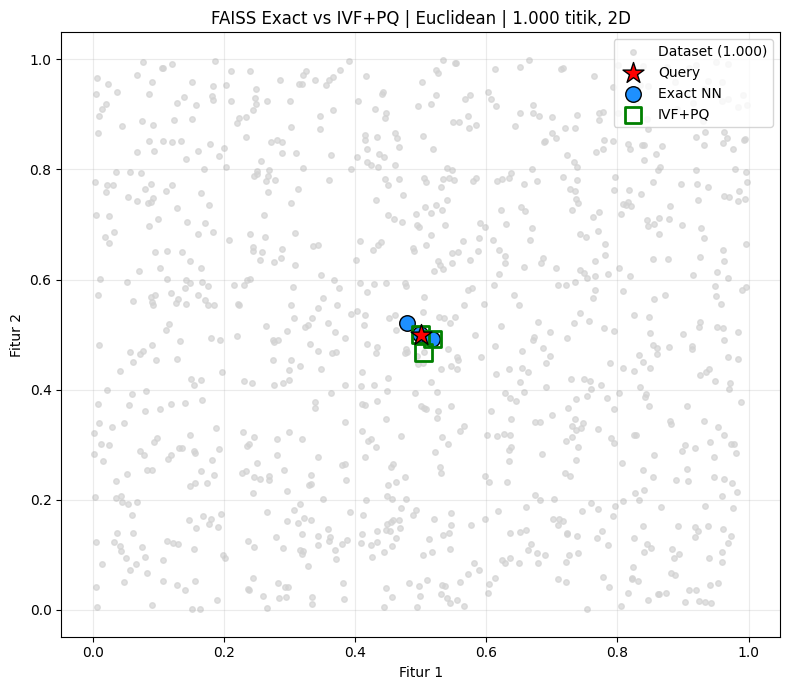

In [6]:
fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(X_for_plot[:, 0], X_for_plot[:, 1], s=16, color='lightgray', alpha=.7, label='Dataset (1.000)')
ax.scatter(q_for_plot[:, 0], q_for_plot[:, 1], s=250, c='red', marker='*',
           edgecolor='black', label='Query', zorder=5)
exact_ids, pq_ids = indices_for_plot
ax.scatter(X_for_plot[exact_ids, 0], X_for_plot[exact_ids, 1],
           s=125, c='dodgerblue', edgecolor='black', label='Exact NN', zorder=3)
valid_pq_ids = [int(i) for i in pq_ids if i >= 0]
ax.scatter(X_for_plot[valid_pq_ids, 0], X_for_plot[valid_pq_ids, 1],
           s=145, facecolors='none', edgecolors='green', marker='s',
           linewidths=2, label='IVF+PQ', zorder=4)
ax.set(title='FAISS Exact vs IVF+PQ | Euclidean | 1.000 titik, 2D',
       xlabel='Fitur 1', ylabel='Fitur 2')
ax.grid(alpha=.25)
ax.legend(loc='best')
plt.tight_layout()
plt.savefig('JS06_Praktikum2_Visualisasi_2D.png', dpi=180)
plt.show()

### 5. Percobaan 2 — 1.000.000 data (2D dan 5D)

Bagian ini menjalankan empat percobaan untuk data lebih besar. **Pastikan RAM tersedia** dan biarkan proses *training* serta *indexing* selesai sebelum menafsirkan waktu pencarian. Komputasi bisa memerlukan beberapa menit, bergantung hardware.

*Jika ingin menguji cepat lebih dulu, jalankan hanya Percobaan 1. Namun untuk memenuhi seluruh tugas, sel ini perlu dijalankan.*

In [7]:
results_large = []

for dim in [2, 5]:
    X_raw, query_raw = generate_data(1_000_000, dim)
    print(f'\nDimensi {dim}: dataset dibuat, ukuran array {X_raw.nbytes/1e6:.1f} MB')
    for metric in ['Euclidean', 'Cosine']:
        print(f'Menjalankan: {metric} | n=1,000,000 | dim={dim} ...')
        t0 = time.perf_counter()
        result, i_ex, i_pq = run_experiment(X_raw, query_raw, metric, dim)
        results_large.append(result)
        print('  Exact:', i_ex, '| IVF+PQ:', i_pq,
              '| Recall@3:', f"{result['Recall@3']:.3f}",
              '| Total durasi percobaan:', f'{time.perf_counter()-t0:.2f}s')
    del X_raw, query_raw
    gc.collect()

large_df = pd.DataFrame(results_large)
display(large_df[cols_show].round(5))


Dimensi 2: dataset dibuat, ukuran array 8.0 MB
Menjalankan: Euclidean | n=1,000,000 | dim=2 ...
  Exact: [16541, 975941, 202] | IVF+PQ: [975941, 16541, 971854] | Recall@3: 0.667 | Total durasi percobaan: 21.39s
Menjalankan: Cosine | n=1,000,000 | dim=2 ...
  Exact: [203681, 191009, 124572] | IVF+PQ: [12413, 11238, 5160] | Recall@3: 0.000 | Total durasi percobaan: 16.56s

Dimensi 5: dataset dibuat, ukuran array 20.0 MB
Menjalankan: Euclidean | n=1,000,000 | dim=5 ...
  Exact: [416143, 972743, 511758] | IVF+PQ: [416143, 972743, 511758] | Recall@3: 1.000 | Total durasi percobaan: 41.90s
Menjalankan: Cosine | n=1,000,000 | dim=5 ...
  Exact: [703343, 208679, 641374] | IVF+PQ: [649453, 427926, 69012] | Recall@3: 0.000 | Total durasi percobaan: 42.64s


,Metrik,Jumlah data,Dimensi,Exact NN index,IVF+PQ index,Waktu Exact (ms),Waktu IVF+PQ (ms),Recall@3
0,Euclidean,1000000,2,"[16541, 975941, 202]","[975941, 16541, 971854]",21.60987,0.83845,0.66667
1,Cosine,1000000,2,"[203681, 191009, 124572]","[12413, 11238, 5160]",2.32786,0.77584,0.00000
2,Euclidean,1000000,5,"[416143, 972743, 511758]","[416143, 972743, 511758]",9.32472,1.00654,1.00000
3,Cosine,1000000,5,"[703343, 208679, 641374]","[649453, 427926, 69012]",4.08630,1.08994,0.00000


### 6. Tabel hasil akhir — delapan percobaan

Kolom waktu menunjukkan **median waktu pencarian per query**, bukan waktu training. Perhitungan `Speedup` memakai waktu Exact dibagi waktu IVF+PQ: nilai di atas 1 menunjukkan IVF+PQ lebih cepat saat lookup. *Recall@3* yang lebih tinggi menunjukkan hasil ANN lebih dekat dengan Exact NN.

In [8]:
hasil = pd.DataFrame(results_small + results_large)

# Tabel sesuai instruksi: distance metrics, jumlah data, dimensi,
# indeks Exact vs Approximate, waktu komputasi, dan ketepatan.
tabel_praktikum = hasil[[
    'Metrik', 'Jumlah data', 'Dimensi',
    'Exact NN index', 'IVF+PQ index',
    'Waktu Exact (ms)', 'Waktu IVF+PQ (ms)',
    'Speedup Exact/IVF+PQ', 'Recall@3'
]].copy()

print('=== TABEL HASIL PRAKTIKUM 2 ===')
display(tabel_praktikum.round(5))
print('\n=== DETAIL KONFIGURASI DAN WAKTU BUILD/TRAIN/ADD ===')
display(hasil[[
    'Metrik', 'Jumlah data', 'Dimensi', 'nlist', 'nprobe', 'PQ m', 'nbits',
    'Build Exact (s)', 'Train IVF+PQ (s)', 'Add IVF+PQ (s)'
]].round(4))

=== TABEL HASIL PRAKTIKUM 2 ===


,Metrik,Jumlah data,Dimensi,Exact NN index,IVF+PQ index,Waktu Exact (ms),Waktu IVF+PQ (ms),Speedup Exact/IVF+PQ,Recall@3
0,Euclidean,1000,2,"[202, 358, 899]","[202, 358, 883]",0.02282,0.02356,0.96851,0.66667
1,Cosine,1000,2,"[640, 999, 341]","[415, 354, 65]",0.02242,0.02002,1.11988,0.00000
2,Euclidean,1000,5,"[870, 383, 53]","[383, 53, 834]",0.02178,0.02071,1.05175,0.66667
3,Cosine,1000,5,"[477, 676, 196]","[346, 477, 119]",0.01904,0.02867,0.66424,0.33333
4,Euclidean,1000000,2,"[16541, 975941, 202]","[975941, 16541, 971854]",21.60987,0.83845,25.77348,0.66667
5,Cosine,1000000,2,"[203681, 191009, 124572]","[12413, 11238, 5160]",2.32786,0.77584,3.00044,0.00000
6,Euclidean,1000000,5,"[416143, 972743, 511758]","[416143, 972743, 511758]",9.32472,1.00654,9.26410,1.00000
7,Cosine,1000000,5,"[703343, 208679, 641374]","[649453, 427926, 69012]",4.08630,1.08994,3.74912,0.00000



=== DETAIL KONFIGURASI DAN WAKTU BUILD/TRAIN/ADD ===


,Metrik,Jumlah data,Dimensi,nlist,nprobe,PQ m,nbits,Build Exact (s),Train IVF+PQ (s),Add IVF+PQ (s)
0,Euclidean,1000,2,10,3,2,4,0.0001,2.2593,0.0159
1,Cosine,1000,2,10,3,2,4,0.0001,1.2396,0.0113
2,Euclidean,1000,5,10,3,5,4,0.0001,3.0354,0.0041
3,Cosine,1000,5,10,3,5,4,0.0001,2.6280,0.0120
4,Euclidean,1000000,2,100,8,2,8,0.0130,14.0673,6.4293
5,Cosine,1000000,2,100,8,2,8,0.0085,11.1834,5.2377
6,Euclidean,1000000,5,100,8,5,8,0.0222,28.2800,13.1936
7,Cosine,1000000,5,100,8,5,8,0.0232,29.0996,13.3028


### 7. Grafik perbandingan waktu pencarian dan Recall@3

Untuk kejelasan, grafik waktu menggunakan sumbu Y logaritmik. Grafik *recall* menggunakan rentang 0 hingga 1 (1 = identik terhadap Exact NN pada tiga hasil teratas).

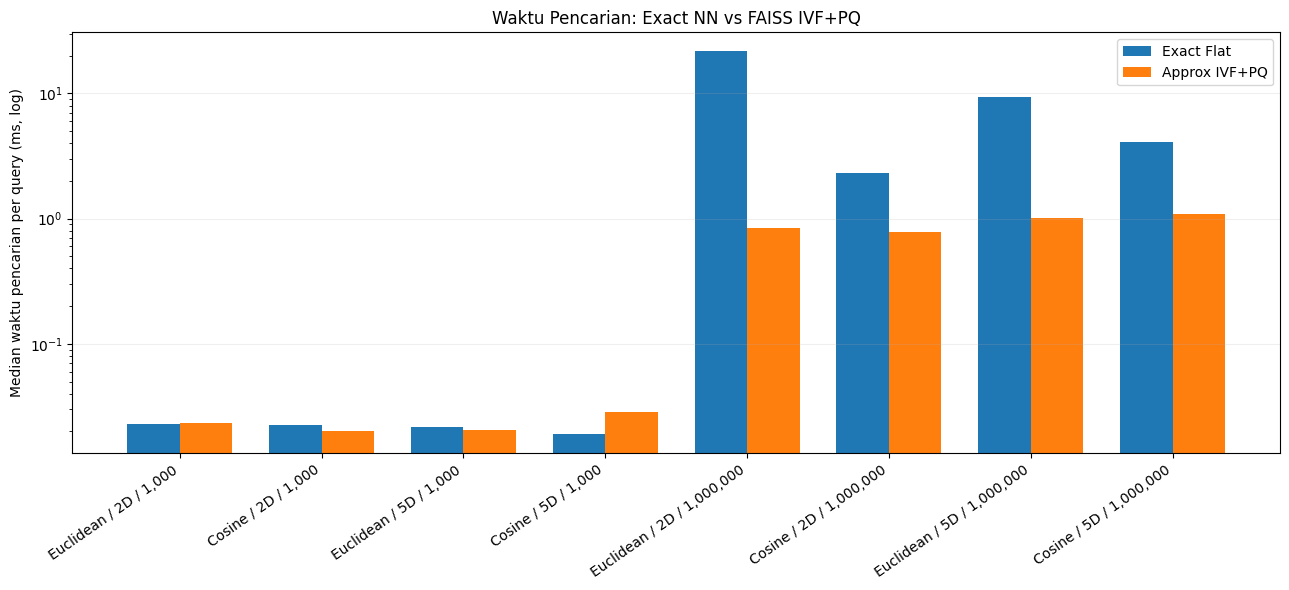

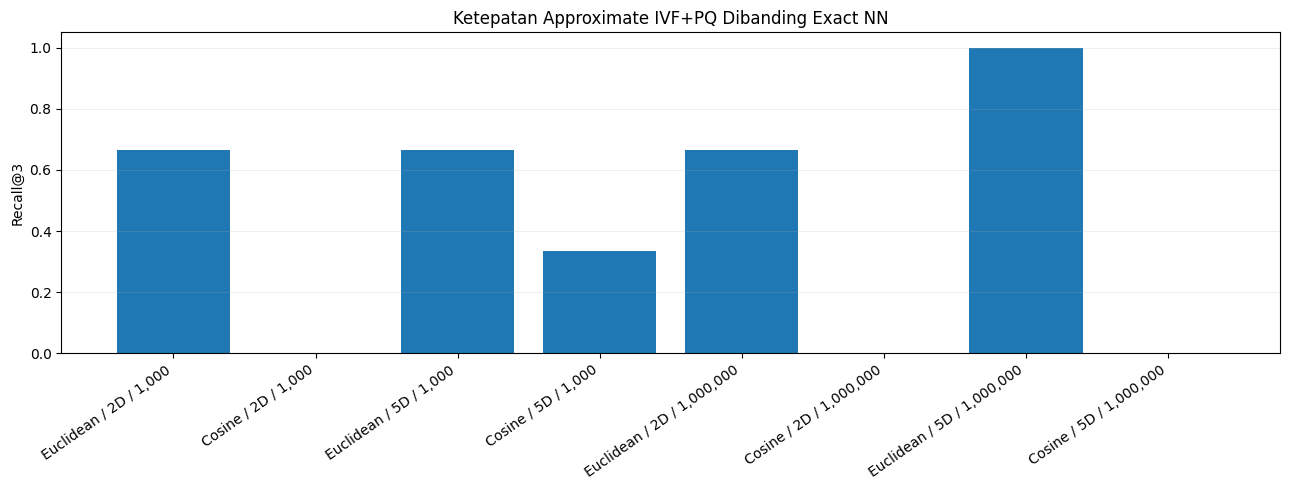

In [9]:
labels_plot = [
    f"{r['Metrik']} / {r['Dimensi']}D / {r['Jumlah data']:,}"
    for _, r in hasil.iterrows()
]
position = np.arange(len(hasil))
w = 0.37

fig, ax = plt.subplots(figsize=(13, 6))
ax.bar(position - w/2, hasil['Waktu Exact (ms)'], width=w,
       label='Exact Flat')
ax.bar(position + w/2, hasil['Waktu IVF+PQ (ms)'], width=w,
       label='Approx IVF+PQ')
ax.set_yscale('log')
ax.set_ylabel('Median waktu pencarian per query (ms, log)')
ax.set_title('Waktu Pencarian: Exact NN vs FAISS IVF+PQ')
ax.set_xticks(position, labels_plot, rotation=35, ha='right')
ax.legend()
ax.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.savefig('JS06_Praktikum2_Perbandingan_Waktu.png', dpi=180)
plt.show()

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(position, hasil['Recall@3'])
ax.set_ylim(0, 1.05)
ax.set_ylabel('Recall@3')
ax.set_title('Ketepatan Approximate IVF+PQ Dibanding Exact NN')
ax.set_xticks(position, labels_plot, rotation=35, ha='right')
ax.grid(axis='y', alpha=.2)
plt.tight_layout()
plt.savefig('JS06_Praktikum2_Recall.png', dpi=180)
plt.show()

### 8. Penyimpanan hasil eksperimen

Simpan dua tabel sebagai CSV agar dapat disisipkan ke laporan praktikum. Grafik pada sel sebelumnya juga tersimpan dalam PNG.

In [10]:
tabel_praktikum.to_csv('JS06_Praktikum2_Hasil_Percobaan.csv', index=False)
hasil.to_csv('JS06_Praktikum2_Hasil_Lengkap.csv', index=False)
print('File tersimpan:')
print('- JS06_Praktikum2_Hasil_Percobaan.csv')
print('- JS06_Praktikum2_Hasil_Lengkap.csv')
print('- JS06_Praktikum2_Visualisasi_2D.png')
print('- JS06_Praktikum2_Perbandingan_Waktu.png')
print('- JS06_Praktikum2_Recall.png')

File tersimpan:
- JS06_Praktikum2_Hasil_Percobaan.csv
- JS06_Praktikum2_Hasil_Lengkap.csv
- JS06_Praktikum2_Visualisasi_2D.png
- JS06_Praktikum2_Perbandingan_Waktu.png
- JS06_Praktikum2_Recall.png


### 9. Analisis dan kesimpulan praktikum

Gunakan tabel hasil yang dihasilkan di atas untuk mendukung kesimpulan berikut:

1. **IndexFlat** adalah pencarian *exact*: seluruh vektor dipertimbangkan sehingga menjadi patokan indeks tetangga terdekat.
2. **IVF+PQ** bersifat *approximate*: hasil indeks dapat berbeda karena penelusuran hanya beberapa inverted list serta penggunaan kompresi Product Quantization. *Recall@3* mengukur tingkat kecocokannya.
3. **Skala data** memengaruhi waktu pencarian. Saat jumlah data meningkat dari 1.000 ke 1.000.000, biaya pemindaian Exact biasanya tumbuh; IVF+PQ dapat menawarkan percepatan pencarian, tetapi **tidak dijamin** selalu lebih cepat untuk setiap konfigurasi dan ukuran kecil.
4. **Dimensi** memengaruhi jumlah komputasi dan efektivitas kompresi. Hasil 2D dan 5D dapat berbeda.
5. **Euclidean vs Cosine:** Euclidean mempertimbangkan jarak posisi mentah; Cosine membandingkan arah vektor setelah normalisasi. Karena itu, tetangga terdekatnya tidak harus sama.
6. **Biaya pembangunan indeks:** untuk IVF+PQ ada waktu `train` dan `add` yang perlu dicatat. Pengukuran *lookup-only* secara sengaja mengecualikannya agar perbandingan mencari tetangga berlangsung adil. Namun, untuk data yang sering berubah, biaya membangun/memperbarui indeks tetap penting untuk evaluasi sistem secara menyeluruh.
7. **Interpretasi waktu:** Pada dataset 1.000, Exact dapat lebih cepat karena tidak ada overhead penelusuran IVF dan decoding PQ; pada dataset besar IVF+PQ lebih berpotensi unggul, bergantung pengaturan `nprobe`, perangkat, dan jumlah query.

#### Catatan teknis tentang modul

- Kode contoh modul `IndexIVFPQ(..., m=2, nbits=8)` pada **1.000 data 2D** berpotensi memberikan peringatan bahwa data training terlalu sedikit untuk 256 centroid PQ. Karena itu percobaan kecil menggunakan `nbits=4` dan percobaan 1 juta menggunakan `nbits=8`.
- FAISS `IndexFlatL2` memberikan **jarak Euclidean kuadrat**, bukan akar jarak Euclidean. Fungsi `show_scores` mengubah nilainya ke akar untuk tampilan (peringkat tetangga tetap sama).
- Benchmark memakai **median 30 pencarian** setelah *warm-up*, bukan waktu satu pencarian tunggal yang mudah terpengaruh fluktuasi sistem.

**Kesimpulan akhir sebaiknya diisi berdasarkan nilai aktual setelah seluruh sel notebook dijalankan, bukan berdasarkan estimasi waktu dari perangkat lain.**

### Referensi

- [FAISS — Index types (Meta AI)](https://github.com/facebookresearch/faiss/wiki/Faiss-indexes): `IndexFlatL2`, `IndexFlatIP`, dan `IndexIVFPQ`.
- [FAISS — FAQ](https://github.com/facebookresearch/faiss/wiki/FAQ): rekomendasi data training PQ dan pengaruh `nprobe`.
- [FAISS — Index factory](https://github.com/facebookresearch/faiss/wiki/The-index-factory): format deklarasi `IVF...,PQ...`.